# LIS 4369: Extensible Enterprise Solutions

## Assignment 4 - Financial Analysis

**Developer:** Joshua Mann

**Program Requirements:**

1. Get
2. Clean
3. Prepare
4. Analyze
5. Visualize

**Note: MUST** use **conda** environment.

In [1]:
# 1. import necessary packages
import sys
import os
import pandas as pd
import pandas as pd
import pandas_datareader as pdr # remote data access for pandas
import yfinance as yf # for financial and market data
import matplotlib.pyplot as plt # visualization
from matplotlib import style # imports style module from matplotlib library
from datetime import datetime as dt # imports datetime class from datetime module

print(sys.version) # print python version
print (os.environ['CONDA_DEFAULT_ENV']) # print conda environment

3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]
testenv


In [2]:
# 2. code, then run demo.py using magic command
%run demo.py


Print number of records: 
2608
Index(['DJIA', 'SP500'], dtype='str')

Print data frame: 
                DJIA    SP500
DATE                         
2016-11-07  18259.60  2131.52
2016-11-08  18332.74  2139.56
2016-11-09  18589.69  2163.26
2016-11-10  18807.88  2167.48
2016-11-11  18847.66  2164.45
...              ...      ...
2026-10-29  52342.56  7720.39
2026-10-30  51770.31  7580.07
2026-11-02  51983.98  7541.40
2026-11-03  51786.72  7568.92
2026-11-04  53356.12      NaN

[2608 rows x 2 columns]

Print first five lines: 
                DJIA    SP500
DATE                         
2016-11-07  18259.60  2131.52
2016-11-08  18332.74  2139.56
2016-11-09  18589.69  2163.26
2016-11-10  18807.88  2167.48
2016-11-11  18847.66  2164.45

Print last five lines: 
                DJIA    SP500
DATE                         
2026-10-29  52342.56  7720.39
2026-10-30  51770.31  7580.07
2026-11-02  51983.98  7541.40
2026-11-03  51786.72  7568.92
2026-11-04  53356.12      NaN

Print first 2 lines: 
 

In [3]:
# 3. get S&P500 index 1-year price history from today's date
# define ticker and date range
# note: in stock trading, caret symbol (^) in ticker symbols differentiate stock market indices from individual, tradeable securities
ticker = "^SPX" # or, ^GSPC
end = dt.date.today()
start = dt.datetime(year=end.year-1, month=end.month, day=end.day)

# fetch data using yfinance download method
df_spx_index = yf.download(ticker, start=start, end=end, progress=False)

# print first 5 records
type(df_spx_index) # check type

pandas.DataFrame

In [4]:
# 4. print DataFrame summary
print(df_spx_index.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 251 entries, 2025-11-04 to 2026-11-03
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, ^SPX)   251 non-null    float64
 1   (High, ^SPX)    251 non-null    float64
 2   (Low, ^SPX)     251 non-null    float64
 3   (Open, ^SPX)    251 non-null    float64
 4   (Volume, ^SPX)  251 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.8 KB
None


In [5]:
# 5. note: when changing col names using list, order of list must align with col positions
df_spx_index.columns = ['Close', 'High', 'Low', 'Open', 'Volume']

# note: col name change
print(df_spx_index.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 251 entries, 2025-11-04 to 2026-11-03
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   251 non-null    float64
 1   High    251 non-null    float64
 2   Low     251 non-null    float64
 3   Open    251 non-null    float64
 4   Volume  251 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.8 KB
None


In [6]:
# 6. print first/last 5 records of S&P500 index 1-year price history
df_spx_index

,Close,High,Low,Open,Volume
Date,,,,,
2025-11-04,6771.549805,6820.209961,6766.709961,6788.520020,5739510000
2025-11-05,6796.290039,6829.779785,6763.109863,6769.770020,5939600000
2025-11-06,6720.319824,6796.680176,6707.509766,6787.589844,6051900000
2025-11-07,6728.799805,6730.109863,6631.439941,6696.180176,5926070000
2025-11-10,6832.430176,6841.319824,6770.560059,6785.359863,5366050000
...,...,...,...,...,...
2026-10-28,7743.979980,7758.430176,7718.370117,7735.560059,5466960000
2026-10-29,7720.390137,7732.209961,7690.939941,7699.609863,5827600000
2026-10-30,7580.069824,7637.479980,7527.560059,7631.069824,6149170000


<Axes: title={'center': 'S&P500 index 1-year price history'}, xlabel='Date'>

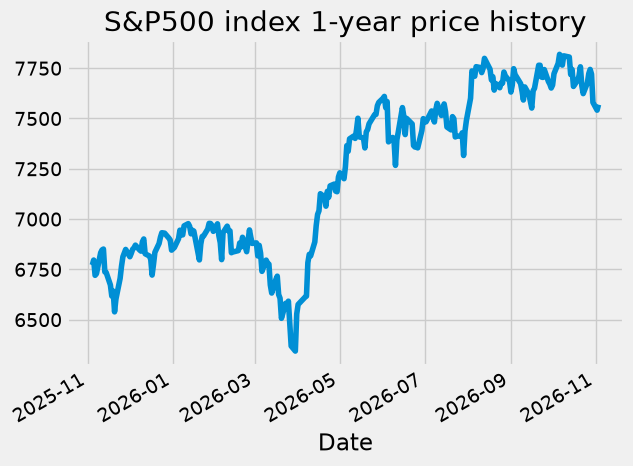

In [7]:
# 7. plot S&P500 index 1-year price history closing prices
df_spx_index['Close'].plot(title='S&P500 index 1-year price history')

In [8]:
# 8. get unemployment data by date (2000 - present)
start = dt.datetime(2000, 1, 1)
end = dt.datetime.now()

df = pdr.DataReader(['LNS13023653', 'LNS13026638'], 'fred', start, end)
df = df.rename(columns={'LNS13023653':'Jobs Lost - Layoff', 'LNS13026638':'Jobs Lost - Permanent'})
df.columns # display new column names

Index(['Jobs Lost - Layoff', 'Jobs Lost - Permanent'], dtype='str')

In [9]:
# a. print number of data prints
print(len(df))

321


In [10]:
# b. display first/last 5 records formatted with thousand separator
df = df*1000 # convert to actual values

df_formatted = pd.concat([df.head(5), df.tail(5)]).style.format('{:,.0f}')
df_formatted

,Jobs Lost - Layoff,Jobs Lost - Permanent
DATE,,
2000-01-01 00:00:00,"753,000","1,165,000"
2000-02-01 00:00:00,"849,000","1,171,000"
2000-03-01 00:00:00,"816,000","1,155,000"
2000-04-01 00:00:00,"707,000","1,083,000"
2000-05-01 00:00:00,"868,000","1,076,000"
2026-05-01 00:00:00,"778,000","1,927,000"
2026-06-01 00:00:00,"768,000","1,769,000"
2026-07-01 00:00:00,"921,000","1,715,000"
2026-08-01 00:00:00,"839,000","1,777,000"


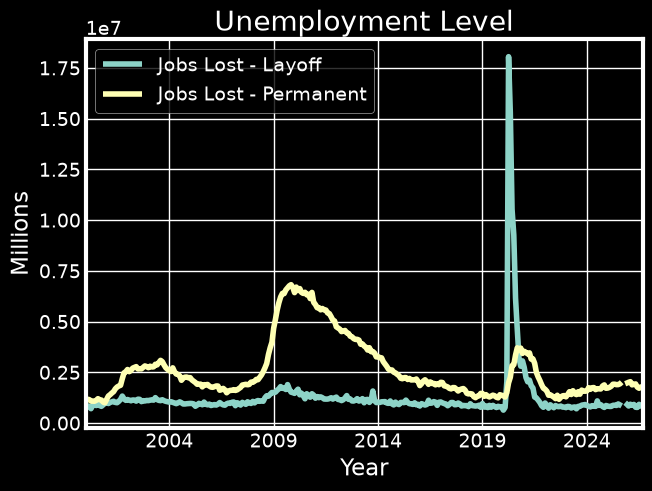

In [11]:
# c. plot unemployment numbers by date
plt.style.use('dark_background') # use different style

df['Jobs Lost - Layoff'].plot()
df['Jobs Lost - Permanent'].plot()
plt.title('Unemployment Level')
plt.xlabel('Year')
plt.ylabel('Millions')
plt.legend()
plt.show()

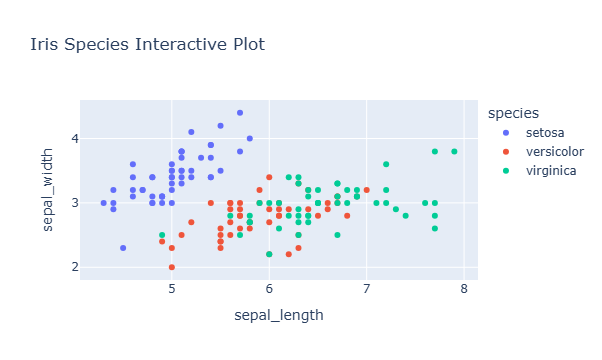

In [12]:
# d. demo interactive plot using Plotly Express and built-in dataset
import plotly.express as px

# i. prepare data
df_iris = px.data.iris()

# ii. create scatter plot using Plotly Express scatter() function
# x-axis: 'sepal_length'; y-axis: 'sepal_width'; 'species' determines point color
fig = px.scatter(df_iris, title="Iris Species Interactive Plot", x="sepal_length", y="sepal_width", color="species")

# iii. display plot
fig.show()

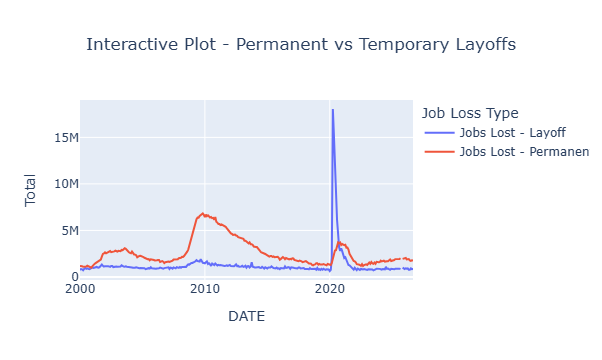

In [13]:
# e. create employment interactive visualization
import plotly.express as px

# set line() function parameters
fig = px.line(df, y=['Jobs Lost - Layoff',
                     'Jobs Lost - Permanent'],
              title='Interactive Plot - Permanent vs Temporary Layoffs',
              labels={'value':'Total',
                      'variable':'Job Loss Type'})

# center title, and make single hover label appear for each point per trace as cursor ('x unified')
fig.update_layout(title_x=0.5, hovermode='x unified')
fig.show()

In [14]:
# f. save to unemployment.csv
df.to_csv('unemployment.csv')

In [15]:
# 9. display inflation percentage values by date

start = dt.datetime (1960, 1, 1)
end = dt.datetime.now()

df = pdr.DataReader(['FPCPITOTLZGUSA'], 'fred', start, end)
df = df.rename(columns={'FPCPITOTLZGUSA':'U.S. Inflation'})
df.columns # display new column names

Index(['U.S. Inflation'], dtype='str')

In [16]:
# a. display number of data points
print(len(df))

65


In [17]:
# b. display first/last 5 records formatted to two decimal places
df_formatted = pd.concat([df.head(5), df.tail(5)]).style.format('{:,.2f}')
df_formatted

,U.S. Inflation
DATE,
1960-01-01 00:00:00,1.46
1961-01-01 00:00:00,1.07
1962-01-01 00:00:00,1.20
1963-01-01 00:00:00,1.24
1964-01-01 00:00:00,1.28
2020-01-01 00:00:00,1.23
2021-01-01 00:00:00,4.70
2022-01-01 00:00:00,8.00
2023-01-01 00:00:00,4.12


In [21]:
# c. show changes on month-to-month basis
df_diff = df['U.S. Inflation'].diff()
df_diff # why does first row contain Nan? ans: gap in dataset

DATE
1960-01-01         NaN
1961-01-01   -0.387252
1962-01-01    0.128049
1963-01-01    0.040896
1964-01-01    0.039242
                ...   
2020-01-01   -0.578626
2021-01-01    3.464274
2022-01-01    3.304941
2023-01-01   -3.886461
2024-01-01   -1.166813
Name: U.S. Inflation, Length: 65, dtype: float64

In [22]:
# d. format changes on month-to-month basis to two decimal places
rounded_number = round(df_diff, 2)
print(rounded_number)

DATE
1960-01-01     NaN
1961-01-01   -0.39
1962-01-01    0.13
1963-01-01    0.04
1964-01-01    0.04
              ... 
2020-01-01   -0.58
2021-01-01    3.46
2022-01-01    3.30
2023-01-01   -3.89
2024-01-01   -1.17
Name: U.S. Inflation, Length: 65, dtype: float64


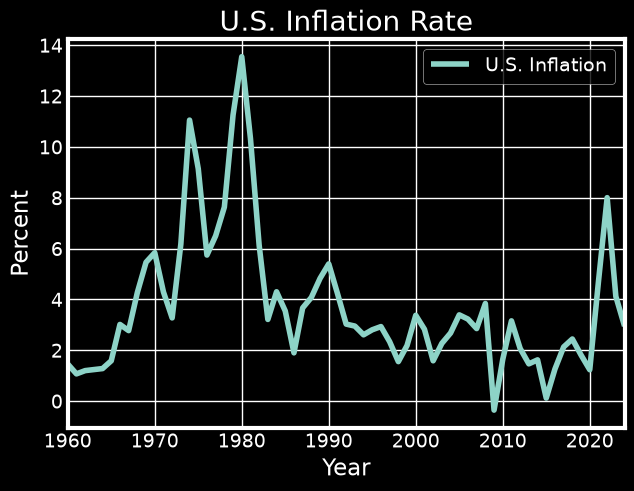

In [23]:
# e. plot inflation numbers by date
plt.style.use('dark_background')

df['U.S. Inflation'].plot()
plt.title('U.S. Inflation Rate')
plt.xlabel('Year')
plt.ylabel('Percent')
plt.legend()
plt.show()

In [24]:
# f. save to inflation.csv
df.to_csv('inflation.csv')